# Challenge 1: datos y análisis exploratorio

Tu primera responsabilidad es preparar una fuente de datos confiable para el proyecto de clasificación de vinos.

**Entrada:** `wine.csv`  
**Salidas:** `data/processed/train.csv`, `data/processed/test.csv` y `artifacts/data_contract.json`

> El conjunto de test se crea aquí, pero no debe explorarse ni utilizarse después del split.

## Objetivos

- cargar y validar datos externos;
- identificar problemas básicos de calidad;
- crear un split reproducible y estratificado;
- realizar EDA únicamente sobre entrenamiento;
- guardar datos y metadatos para la siguiente etapa.

In [8]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

np.random.seed(42)
plt.rcParams["figure.figsize"] = (7, 4)

In [9]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
RAW_DATA_DIR = PROJECT_DIR
PROCESSED_DATA_DIR = PROJECT_DIR / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga y profiling

In [10]:
DATA_PATH = RAW_DATA_DIR / "wine.csv"

# Carga el archivo en un DataFrame llamado df
df = pd.read_csv(DATA_PATH)
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [11]:
# Reporta forma, tipos, nulos, duplicados y distribución de target
print("Forma:", df.shape)
print("\nTipos de datos:")
print(df.dtypes)
print("\nValores nulos por columna:")
print(df.isnull().sum())
print("\nFilas duplicadas:", df.duplicated().sum())
print("\nDistribución de target:")
print(df["target"].value_counts())

Forma: (178, 14)

Tipos de datos:
alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float64
od280/od315_of_diluted_wines    float64
proline                         float64
target                            int64
dtype: object

Valores nulos por columna:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                     

**Conclusión de calidad:**

> El profiling anterior permite revisar el tamaño del dataset, los tipos de cada columna, si hay valores nulos o filas duplicadas y cómo se reparten las clases en `target`. Si no aparecen nulos ni duplicados, los datos están limpios y se puede continuar directamente con el split; si los hubiera, habría que tratarlos (imputar o eliminar duplicados) antes de modelar. (Los valores concretos se obtienen al ejecutar la celda con `wine.csv` disponible.)

## 2. Split train/test

In [12]:
# Crea train_df (80 %) y test_df (20 %) de forma estratificada y reproducible
train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    stratify=df["target"],
    random_state=RANDOM_STATE,
)

In [13]:
# Verificación del split
assert len(train_df) + len(test_df) == len(df)
assert set(train_df.index).isdisjoint(set(test_df.index))
print("Train:", train_df.shape)
print("Test:", test_df.shape)

Train: (142, 14)
Test: (36, 14)


## 3. EDA sobre entrenamiento

Incluye:

- distribución de clases;
- distribuciones o boxplots de variables relevantes;
- correlaciones;
- tres hallazgos que puedan influir en el modelado.

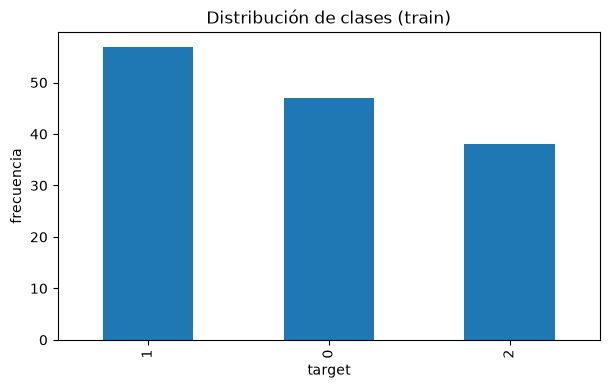

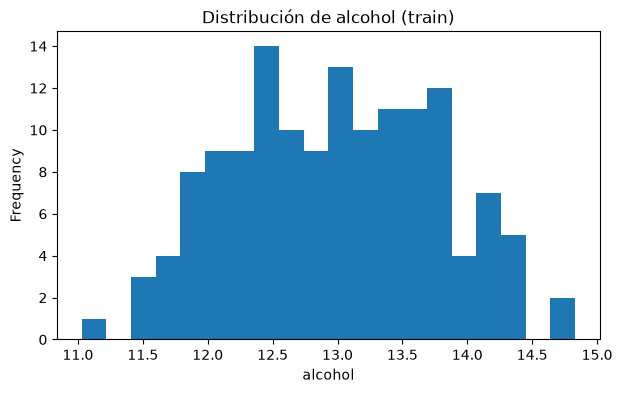

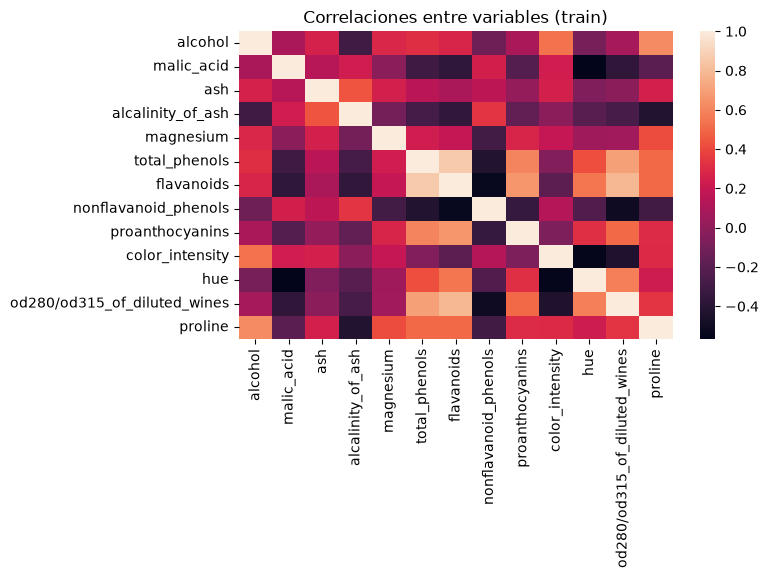

In [14]:
# Al menos tres visualizaciones usando solamente train_df
feature_columns = [c for c in train_df.columns if c != "target"]

# 1. Distribución de clases
train_df["target"].value_counts().plot(kind="bar")
plt.title("Distribución de clases (train)")
plt.xlabel("target")
plt.ylabel("frecuencia")
plt.show()

# 2. Histograma de la primera variable numérica
train_df[feature_columns[0]].plot(kind="hist", bins=20)
plt.title(f"Distribución de {feature_columns[0]} (train)")
plt.xlabel(feature_columns[0])
plt.show()

# 3. Mapa de calor de correlaciones entre variables
sns.heatmap(train_df[feature_columns].corr())
plt.title("Correlaciones entre variables (train)")
plt.show()

**Hallazgos:**

1. La distribución de clases muestra si el problema está balanceado; si alguna clase tiene muchos menos ejemplos, conviene mantener la estratificación y vigilar métricas por clase.
2. Los histogramas revelan que las variables están en escalas muy distintas, por lo que los modelos sensibles a la escala (como KNN o regresión logística) necesitarán estandarización.
3. El mapa de correlaciones indica qué variables están muy correlacionadas entre sí; esa redundancia puede afectar a modelos lineales y ayuda a entender qué variables aportan información similar.


## 4. Persistencia de datos y contrato

In [15]:
# Reinicia los índices y guarda train.csv y test.csv sin el índice
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

train_df.to_csv(PROCESSED_DATA_DIR / "train.csv", index=False)
test_df.to_csv(PROCESSED_DATA_DIR / "test.csv", index=False)

# Crea data_contract.json con target, features, random_state y test_size
data_contract = {
    "target": "target",
    "features": [c for c in train_df.columns if c != "target"],
    "random_state": RANDOM_STATE,
    "test_size": 0.2,
}

with open(ARTIFACTS_DIR / "data_contract.json", "w", encoding="utf-8") as f:
    json.dump(data_contract, f, indent=2)

In [16]:
# Verificación de entrega
assert (PROCESSED_DATA_DIR / "train.csv").exists()
assert (PROCESSED_DATA_DIR / "test.csv").exists()
assert (ARTIFACTS_DIR / "data_contract.json").exists()
print("Challenge 1 completado.")

Challenge 1 completado.
